# TP2 — Modèles génératifs PyTorch sur MNIST

**Première partie — Pr. Mohamed YOUSSFI.** Ce notebook réalise les quatre étapes demandées : chargement MNIST, classifieur discriminatif, autoencodeur simple et VAE. Il reprend l'architecture du support fourni et ajoute une évaluation séparée sur le jeu de test, des graphiques et une génération reproductible.

Exécuter les cellules dans l'ordre. Les données sont téléchargées dans `data/` au premier lancement. Le GPU CUDA est utilisé automatiquement s'il est disponible.

## 0. Environnement

Dans VS Code, ouvrir ce dossier `TP2`, lancer `uv sync`, puis choisir l'interpréteur `.venv` comme noyau du notebook. Le projet utilise Python 3.11 et les dépendances déclarées dans `pyproject.toml`.

In [1]:
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torcheval.metrics import MulticlassAccuracy

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device={device}")

PyTorch 2.14.1+cpu | device=cpu


## 1. Chargement du dataset MNIST

MNIST contient 60 000 images d'entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28. `ToTensor()` place les pixels dans [0, 1]. Le jeu de test n'est jamais utilisé pour modifier les poids.

Train: 60000 | Test: 10000


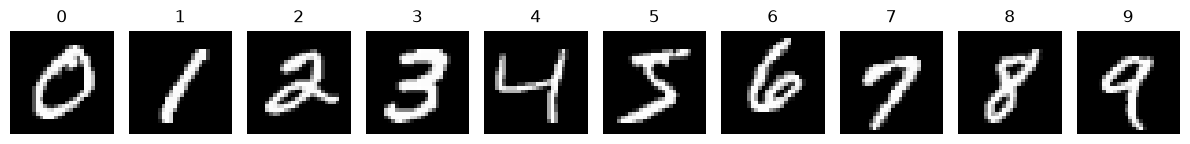

In [2]:
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=0)
print(f"Train: {len(train_dataset)} | Test: {len(test_dataset)}")
fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for digit, ax in enumerate(axes):
    index = (train_dataset.targets == digit).nonzero()[0].item()
    ax.imshow(train_dataset[index][0].squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(digit)); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Modèle discriminatif

Le classifieur estime $P(y\mid x)$ à partir des 784 pixels. La fonction `CrossEntropyLoss` compare les logits aux étiquettes. L'accuracy est calculée sur les 10 000 images de test avec `torcheval`.

In [3]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, x):
        return self.net(x)

def train_classifier(model, loader, epochs=3):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); optimizer.step()
            total += loss.item() * x.size(0)
        history.append(total / len(loader.dataset))
        print(f"Classifieur {epoch + 1}/{epochs}: CE train={history[-1]:.4f}")
    return history

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    metric = MulticlassAccuracy(device=device)
    total = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        metric.update(logits, y)
        total += F.cross_entropy(logits, y, reduction="sum").item()
    return total / len(loader.dataset), metric.compute().item()

classifier = Classifier().to(device)
classifier_history = train_classifier(classifier, train_loader)
classifier_test_ce, classifier_accuracy = evaluate_classifier(classifier, test_loader)
print(f"Test: CE={classifier_test_ce:.4f} | accuracy={classifier_accuracy:.2%}")

Classifieur 1/3: CE train=0.5167


Classifieur 2/3: CE train=0.2399


Classifieur 3/3: CE train=0.1831


Test: CE=0.1614 | accuracy=95.21%


Le classifieur associe une image à une classe ; sa sortie n'est pas une image. La matrice de confusion montre les chiffres les plus souvent confondus.

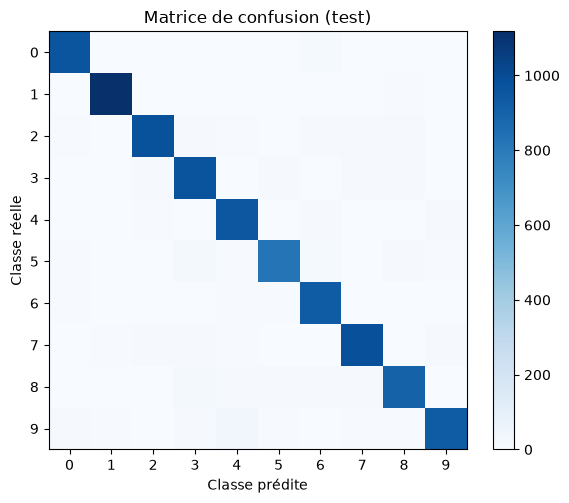

In [4]:
confusion = torch.zeros(10, 10, dtype=torch.int64)
classifier.eval()
with torch.no_grad():
    for x, y in test_loader:
        pred = classifier(x.to(device)).argmax(1).cpu()
        confusion += torch.bincount(y * 10 + pred, minlength=100).reshape(10, 10)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(confusion, cmap="Blues")
ax.set(xlabel="Classe prédite", ylabel="Classe réelle", title="Matrice de confusion (test)")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

## 3. Autoencodeur simple

L'encodeur transforme l'image en un point latent de dimension 2. Le décodeur reconstruit une image. La perte est la MSE moyenne par pixel. Les étiquettes ne servent pas à l'entraînement ; elles colorent uniquement l'espace latent.

In [5]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                                     nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 32), nn.ReLU(),
                                     nn.Linear(32, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid())

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))

def train_autoencoder(model, loader, epochs=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    for epoch in range(epochs):
        model.train(); total = 0.0
        for x, _ in loader:
            x = x.to(device)
            optimizer.zero_grad()
            loss = F.mse_loss(model(x), x)
            loss.backward(); optimizer.step()
            total += loss.item() * x.size(0)
        history.append(total / len(loader.dataset))
        print(f"AE {epoch + 1}/{epochs}: MSE train={history[-1]:.4f}")
    return history

@torch.no_grad()
def evaluate_autoencoder(model, loader):
    model.eval(); total = 0.0
    for x, _ in loader:
        x = x.to(device)
        total += F.mse_loss(model(x), x, reduction="sum").item()
    return total / (len(loader.dataset) * 784)

ae = Autoencoder().to(device)
ae_history = train_autoencoder(ae, train_loader)
ae_test_mse = evaluate_autoencoder(ae, test_loader)
print(f"Test: MSE par pixel={ae_test_mse:.4f}")

AE 1/5: MSE train=0.0751


AE 2/5: MSE train=0.0545


AE 3/5: MSE train=0.0523


AE 4/5: MSE train=0.0506


AE 5/5: MSE train=0.0491


Test: MSE par pixel=0.0486


### Reconstructions et espace latent de l'AE

Les reconstructions sont comparées aux mêmes images d'origine. Chaque point du nuage représente une image de test encodée ; la couleur indique son chiffre.

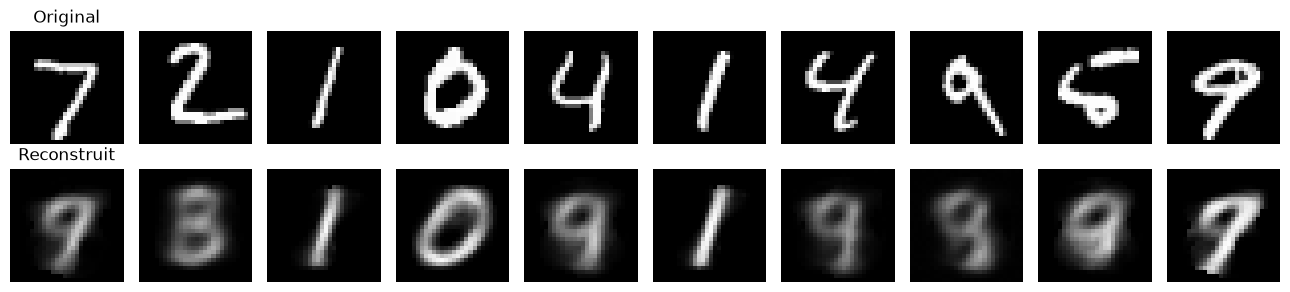

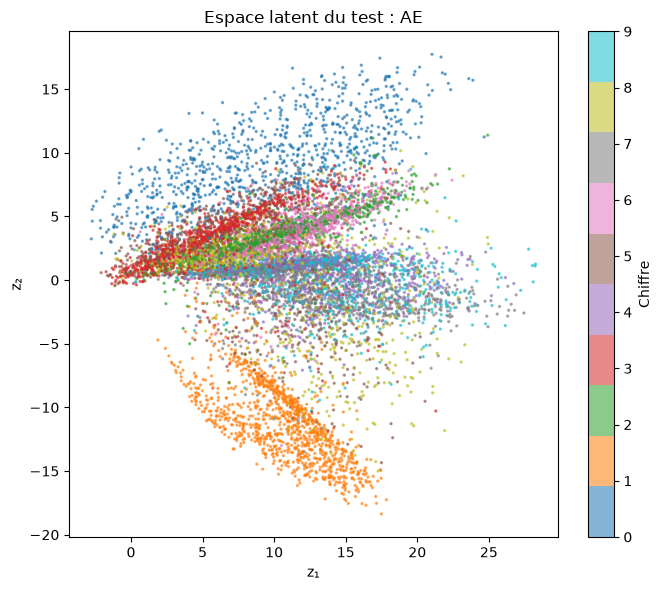

In [6]:
@torch.no_grad()
def show_reconstructions(model, loader, vae=False):
    model.eval()
    x, _ = next(iter(loader))
    x = x[:10].to(device)
    reconstruction = model(x)[0] if vae else model(x)
    fig, axes = plt.subplots(2, 10, figsize=(13, 3))
    for i in range(10):
        for row, image in enumerate((x[i], reconstruction[i])):
            axes[row, i].imshow(image.cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
            axes[row, i].axis("off")
    axes[0, 0].set_title("Original"); axes[1, 0].set_title("Reconstruit")
    plt.tight_layout(); plt.show()

@torch.no_grad()
def show_latent(model, loader, vae=False):
    model.eval(); points, labels = [], []
    for x, y in loader:
        x = x.to(device)
        z = model.encode(x)[0] if vae else model.encode(x)
        points.append(z.cpu()); labels.append(y)
    points = torch.cat(points).numpy(); labels = torch.cat(labels).numpy()
    fig, ax = plt.subplots(figsize=(7, 6))
    scatter = ax.scatter(points[:, 0], points[:, 1], c=labels, cmap="tab10", s=2, alpha=.55)
    fig.colorbar(scatter, ax=ax, ticks=range(10), label="Chiffre")
    ax.set(xlabel="z₁", ylabel="z₂", title="Espace latent du test : " + ("VAE" if vae else "AE"))
    plt.tight_layout(); plt.show()

show_reconstructions(ae, test_loader)
show_latent(ae, test_loader)

Un AE peut décoder un point interpolé entre deux images connues, mais son espace latent n'est pas contraint à suivre une loi simple. Un point choisi au hasard peut donc produire une image peu plausible.

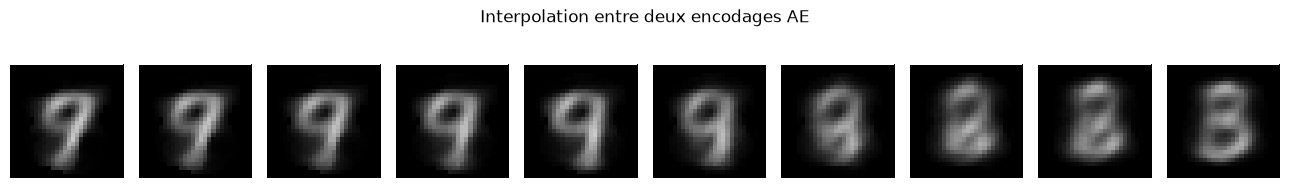

In [7]:
ae.eval()
with torch.no_grad():
    x, _ = next(iter(test_loader))
    endpoints = ae.encode(x[:2].to(device))
    alpha = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    interpolations = ae.decode((1 - alpha) * endpoints[0] + alpha * endpoints[1]).cpu()
fig, axes = plt.subplots(1, 10, figsize=(13, 2))
for ax, image in zip(axes, interpolations):
    ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1); ax.axis("off")
fig.suptitle("Interpolation entre deux encodages AE"); plt.tight_layout(); plt.show()

## 4. Autoencodeur variationnel (VAE)

L'encodeur estime $\mu$ et $\log\sigma^2$ de $q(z\mid x)$. Le rééchantillonnage $z=\mu+\sigma\epsilon$, avec $\epsilon\sim\mathcal N(0,I)$, conserve les gradients. La perte par image est la somme de l'entropie croisée binaire des pixels et de $\beta D_{KL}(q(z\mid x)\Vert\mathcal N(0,I))$, avec $\beta=1$. La BCE et la KL sont toutes deux sommées sur leurs dimensions avant d'être divisées par la taille du dataset.

In [8]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                     nn.Linear(256, 64), nn.ReLU())
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 64), nn.ReLU(),
                                     nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(.5 * logvar) * torch.randn_like(mu)
        return self.decode(z), mu, logvar

def vae_loss(reconstruction, x, mu, logvar, beta=1.0):
    rec = F.binary_cross_entropy(reconstruction, x, reduction="sum")
    kl = -.5 * torch.sum(1 + logvar - mu.square() - logvar.exp())
    return rec + beta * kl, rec, kl

def train_vae(model, loader, epochs=10, beta=1.0):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    for epoch in range(epochs):
        model.train(); sums = torch.zeros(3)
        for x, _ in loader:
            x = x.to(device)
            optimizer.zero_grad()
            reconstruction, mu, logvar = model(x)
            loss, rec, kl = vae_loss(reconstruction, x, mu, logvar, beta)
            loss.backward(); optimizer.step()
            sums += torch.tensor([loss.item(), rec.item(), kl.item()])
        values = (sums / len(loader.dataset)).tolist()
        history.append(values)
        print(f"VAE {epoch + 1}/{epochs}: loss={values[0]:.2f} | rec={values[1]:.2f} | KL={values[2]:.2f}")
    return history

@torch.no_grad()
def evaluate_vae(model, loader, beta=1.0):
    model.eval(); sums = torch.zeros(3)
    for x, _ in loader:
        x = x.to(device)
        # La moyenne postérieure donne une reconstruction de test déterministe.
        mu, logvar = model.encode(x)
        loss, rec, kl = vae_loss(model.decode(mu), x, mu, logvar, beta)
        sums += torch.tensor([loss.item(), rec.item(), kl.item()])
    return (sums / len(loader.dataset)).tolist()

vae = VAE().to(device)
vae_history = train_vae(vae, train_loader)
vae_test_loss, vae_test_rec, vae_test_kl = evaluate_vae(vae, test_loader)
print(f"Test (z=μ): loss={vae_test_loss:.2f} | rec={vae_test_rec:.2f} | KL={vae_test_kl:.2f} par image")

VAE 1/10: loss=213.50 | rec=210.16 | KL=3.34


VAE 2/10: loss=174.68 | rec=170.27 | KL=4.41


VAE 3/10: loss=166.48 | rec=161.41 | KL=5.07


VAE 4/10: loss=161.92 | rec=156.60 | KL=5.32


VAE 5/10: loss=158.65 | rec=153.17 | KL=5.47


...

VAE 7/10: loss=154.92 | rec=149.32 | KL=5.59


VAE 8/10: loss=153.68 | rec=148.02 | KL=5.67


VAE 9/10: loss=152.62 | rec=146.87 | KL=5.75


VAE 10/10: loss=151.67 | rec=145.87 | KL=5.80


Test (z=μ): loss=150.68 | rec=144.92 | KL=5.76 par image


### Reconstructions, distribution latente et nouveaux chiffres

Pour la visualisation, les reconstructions utilisent un échantillon $z$ ; l'évaluation chiffrée utilise $\mu$ pour rester stable d'une exécution à l'autre. De nouvelles images proviennent de $z\sim\mathcal N(0,I)$, sans image d'entrée.

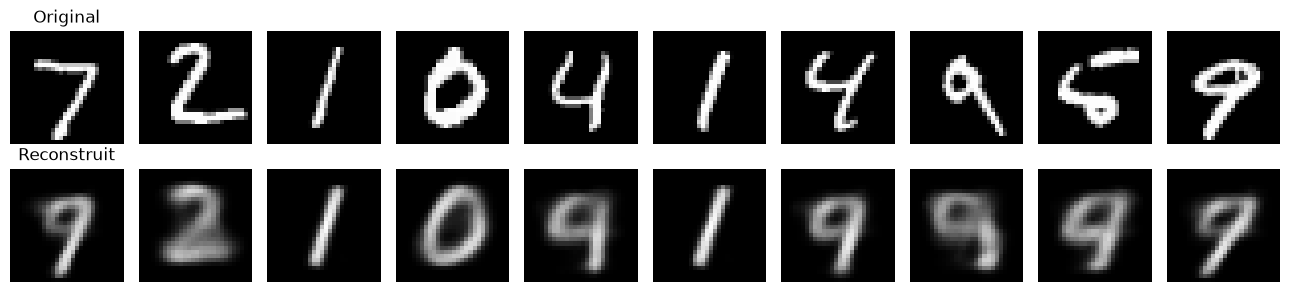

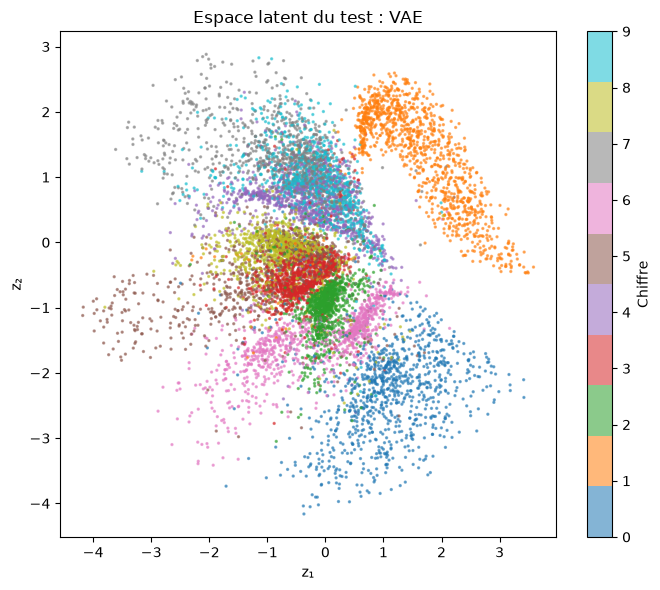

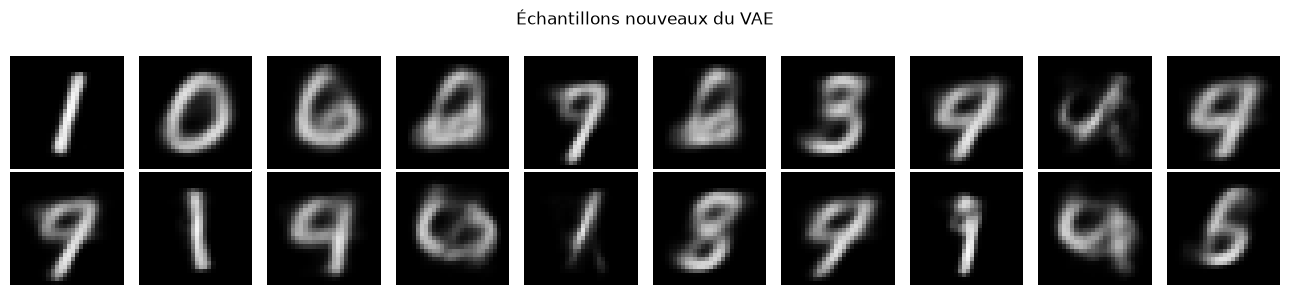

In [9]:
show_reconstructions(vae, test_loader, vae=True)
show_latent(vae, test_loader, vae=True)
vae.eval()
with torch.no_grad():
    generator = torch.Generator(device=device).manual_seed(SEED)
    z = torch.randn((20, 2), generator=generator, device=device)
    generated = vae.decode(z).cpu()
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for ax, image in zip(axes.flat, generated):
    ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1); ax.axis("off")
fig.suptitle("Échantillons nouveaux du VAE"); plt.tight_layout(); plt.show()

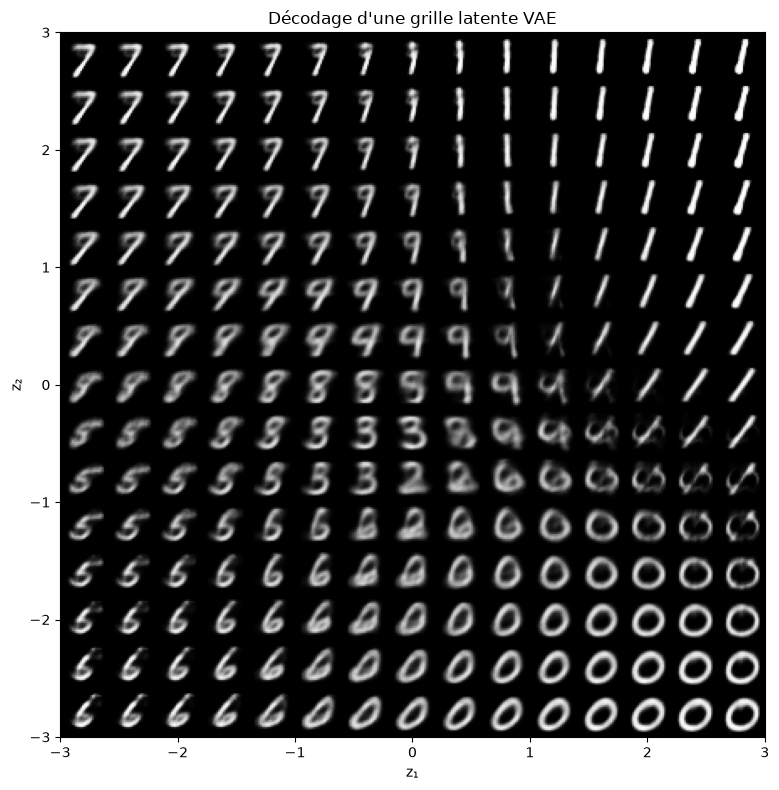

In [10]:
grid = torch.linspace(-3, 3, 15, device=device)
yy, xx = torch.meshgrid(grid.flip(0), grid, indexing="ij")
with torch.no_grad():
    decoded = vae.decode(torch.stack((xx.flatten(), yy.flatten()), dim=1)).cpu()
mosaic = decoded.reshape(15, 15, 28, 28).permute(0, 2, 1, 3).reshape(420, 420)
plt.figure(figsize=(8, 8))
plt.imshow(mosaic, cmap="gray", vmin=0, vmax=1, extent=(-3, 3, -3, 3))
plt.xlabel("z₁"); plt.ylabel("z₂"); plt.title("Décodage d'une grille latente VAE")
plt.tight_layout(); plt.show()

## 5. Bilan

Les métriques ci-dessous portent sur le jeu de test complet. L'accuracy du classifieur et la MSE de l'AE ne sont pas directement comparables à la BCE + KL du VAE : elles mesurent des objectifs différents. La grille latente permet d'inspecter la continuité des chiffres générés. Un latent à deux dimensions facilite la visualisation mais limite la qualité des reconstructions.

Classifieur : accuracy test = 95.21%, CE = 0.1614
AE          : MSE test/pixel = 0.0486
VAE         : perte test/image = 150.68 (BCE=144.92, KL=5.76)


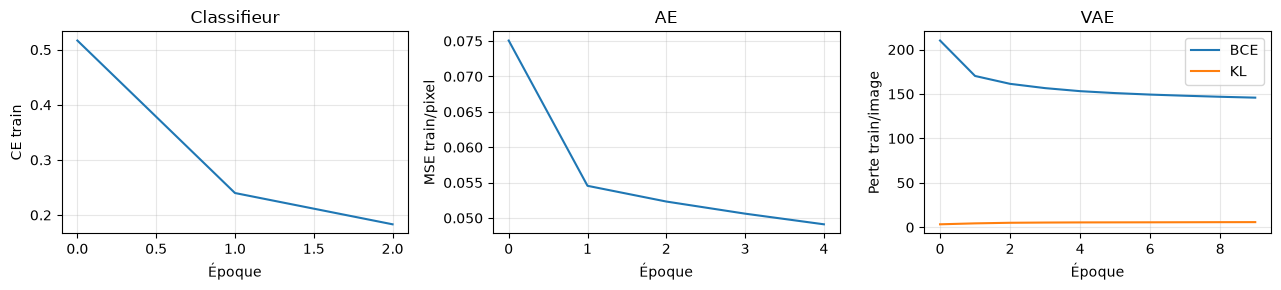

In [11]:
print(f"Classifieur : accuracy test = {classifier_accuracy:.2%}, CE = {classifier_test_ce:.4f}")
print(f"AE          : MSE test/pixel = {ae_test_mse:.4f}")
print(f"VAE         : perte test/image = {vae_test_loss:.2f} (BCE={vae_test_rec:.2f}, KL={vae_test_kl:.2f})")
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
axes[0].plot(classifier_history); axes[0].set(title="Classifieur", xlabel="Époque", ylabel="CE train")
axes[1].plot(ae_history); axes[1].set(title="AE", xlabel="Époque", ylabel="MSE train/pixel")
axes[2].plot([h[1] for h in vae_history], label="BCE")
axes[2].plot([h[2] for h in vae_history], label="KL")
axes[2].set(title="VAE", xlabel="Époque", ylabel="Perte train/image"); axes[2].legend()
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); plt.show()